# ch05_2. ResNet18 전이학습

## 개요

- 사전학습된 ResNet18을 불러옵니다.
- Feature Extraction(피처 익스트랙션, 특징 추출)으로 `fc`만 학습합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import copy
import random
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import InterpolationMode

### 1) 난수 시드와 실행 장치

```text
ImageNet 사전학습 ResNet18
→ CIFAR-10용 fc 교체
→ 1단계: fc만 학습
→ 2단계: layer4 + fc 미세조정
→ 시험 성능 비교
→ 혼동행렬과 오답 분석
→ 모델 저장·복원
```

| 단계 | 학습 범위 | 목적 |
|---|---|---|
| Feature Extraction | `fc` | 기존 특징을 그대로 사용하여 빠르게 분류 |
| Fine-Tuning | `layer4 + fc` | 고급 특징을 CIFAR-10에 맞게 조정 |

ResNet18의 앞쪽 계층은 선, 경계, 색상처럼 여러 이미지에 공통으로 나타나는 특징을 학습합니다. 뒤쪽 계층은 사물의 형태처럼 더 복잡한 특징을 학습합니다.

```text
입력 이미지
→ 앞쪽 계층: 선·경계·색상
→ 중간 계층: 질감·부분 형태
→ 뒤쪽 계층: 복잡한 객체 특징
→ fc: 최종 클래스 분류
```

\[
\mathbf{z}=f_{\theta}(\mathbf{x})
\]

\[
\hat{\mathbf{y}}=g_{\phi}(\mathbf{z})
\]

- $f_{\theta}$: 사전학습된 특징 추출부
- $g_{\phi}$: 새로 교체한 분류층
- Feature Extraction에서는 $\theta$를 고정하고 $\phi$만 학습합니다.

\[
(\theta_{4},\phi)
\leftarrow
(\theta_{4},\phi)
-\eta\nabla_{(\theta_{4},\phi)}\mathcal{L}
\]

- $\theta_{4}$: `layer4`의 가중치
- $\phi$: `fc`의 가중치
- $\eta$: Learning Rate(러닝 레이트, 학습률)
- $\mathcal{L}$: 손실함수

Fine-Tuning에서는 뒤쪽 특징 추출부와 분류층을 함께 조금씩 조정합니다.

코랩에서 위에서부터 순서대로 실행합니다. GPU(지피유, 그래픽 처리 장치)가 있으면 자동으로 사용합니다.

In [3]:
SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch 버전:", torch.__version__)

print("실행 장치:", device)

PyTorch 버전: 2.13.0+cu130
실행 장치: cuda


### 2) 실습 설정

- `QUICK_RUN = True`: 적은 데이터와 Epoch(에포크, 전체 데이터 반복 횟수)로 전체 흐름을 빠르게 확인합니다.
- `QUICK_RUN = False`: 전체 데이터로 학습합니다.
- CIFAR-10 원본 이미지는 32×32이지만, 사전학습 ResNet18의 입력 규격에 맞춰 224×224로 확대합니다.

> 빠른 실행 결과는 기능 확인용입니다. 최종 성능 비교에는 전체 학습을 사용합니다.

In [4]:
QUICK_RUN = True

BATCH_SIZE = 64

FEATURE_EPOCHS = 1 if QUICK_RUN else 4

FINE_TUNING_EPOCHS = 1 if QUICK_RUN else 6

FEATURE_LR = 1e-3

BACKBONE_LR = 1e-4

FC_LR = 5e-4

VALIDATION_SIZE = 5_000

NUMBER_OF_WORKERS = 2

print("Quick Run:", QUICK_RUN)

print("Feature Extraction Epoch:", FEATURE_EPOCHS)

print("Fine-Tuning Epoch:", FINE_TUNING_EPOCHS)

Quick Run: True
Feature Extraction Epoch: 1
Fine-Tuning Epoch: 1


### 3) 데이터 전처리 설정

`ResNet18_Weights.DEFAULT`는 TorchVision(토치비전, 이미지 처리용 PyTorch 라이브러리)의 권장 사전학습 가중치를 선택합니다.

평가 데이터에는 `weights.transforms()`를 그대로 사용합니다.

```text
Resize
→ Center Crop
→ Tensor 변환
→ ImageNet 평균·표준편차 정규화
```

훈련 데이터에는 좌우 반전과 무작위 자르기를 추가합니다.

In [5]:
weights = ResNet18_Weights.DEFAULT

evaluation_transform = weights.transforms()

IMAGENET_MEAN = (0.485, 0.456, 0.406)

IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.7, 1.0),
        interpolation=InterpolationMode.BILINEAR,
        antialias=True,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("사전학습 가중치:", weights)

print("평가 전처리:")

print(evaluation_transform)

사전학습 가중치: ResNet18_Weights.IMAGENET1K_V1
평가 전처리:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


### 4) CIFAR-10 데이터 준비

공식 훈련 데이터 50,000개를 훈련용과 검증용으로 나눕니다.

```text
훈련 데이터 45,000개
검증 데이터 5,000개
시험 데이터 10,000개
```

훈련 데이터만 무작위 증강을 적용하고, 검증·시험 데이터에는 평가용 전처리를 적용합니다.

In [6]:
train_source = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=True,
    transform=train_transform,
)

validation_source = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=False,
    transform=evaluation_transform,
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    download=True,
    transform=evaluation_transform,
)

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(len(train_source), generator=generator).tolist()

train_indices = indices[:-VALIDATION_SIZE]

validation_indices = indices[-VALIDATION_SIZE:]

100.0%


### 5) 빠른 실행용 데이터 축소

In [7]:
if QUICK_RUN:
    train_indices = train_indices[:3_000]
    validation_indices = validation_indices[:1_000]
    test_dataset = Subset(test_dataset, range(1_000))

### 6) 학습·검증 Subset 만들기

In [8]:
train_dataset = Subset(train_source, train_indices)

validation_dataset = Subset(validation_source, validation_indices)

### 7) DataLoader 생성 함수

In [9]:
def make_loader(dataset, shuffle):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUMBER_OF_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

### 8) DataLoader 준비

In [10]:
train_loader = make_loader(train_dataset, shuffle=True)

validation_loader = make_loader(validation_dataset, shuffle=False)

test_loader = make_loader(test_dataset, shuffle=False)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

class_names_ko = [
    "비행기", "자동차", "새", "고양이", "사슴",
    "개", "개구리", "말", "배", "트럭",
]

print("훈련 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("시험 데이터:", len(test_dataset))

훈련 데이터: 3000
검증 데이터: 1000
시험 데이터: 1000


### 9) 배치 데이터 확인

정규화된 이미지를 화면에 표시하려면 다음 순서로 원래 범위에 가깝게 되돌립니다.

\[
\mathbf{x}_{\mathrm{display}}
=
\mathbf{x}_{\mathrm{normalized}}\boldsymbol{\sigma}
+
\boldsymbol{\mu}
\]

- $\boldsymbol{\mu}$: ImageNet 평균
- $\boldsymbol{\sigma}$: ImageNet 표준편차

미니배치 Shape: torch.Size([64, 3, 224, 224])


/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 47085 (\N{HANGUL SYLLABLE REOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 48176 (\N{HANGUL SYLLABLE BAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_101322/67406622.py:21: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_lay

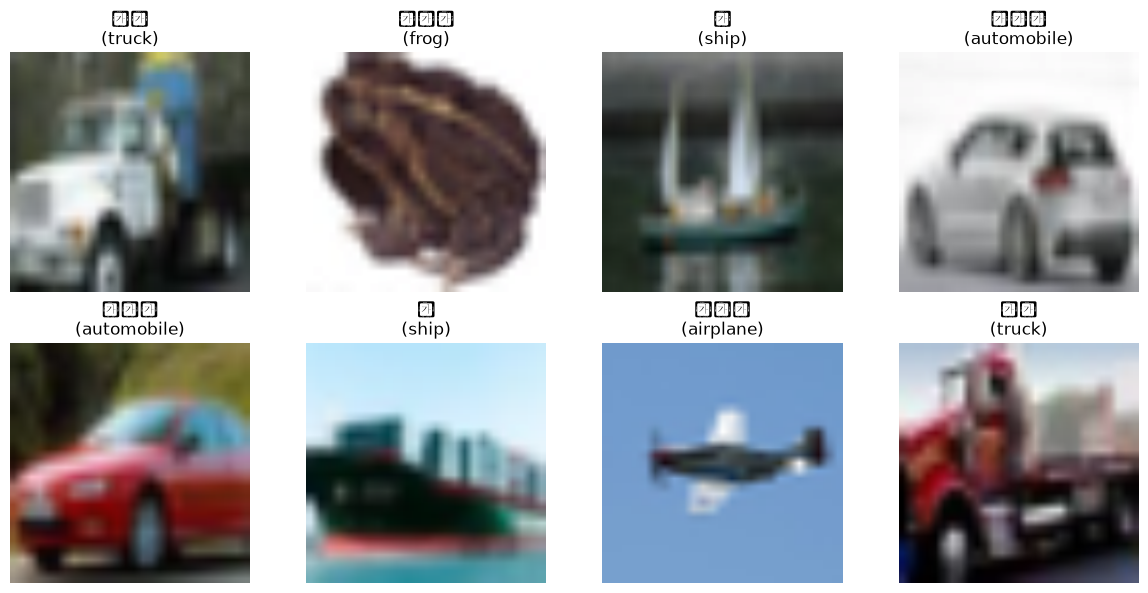

In [11]:
def denormalize(image):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (image.cpu() * std + mean).clamp(0, 1)

sample_images, sample_labels = next(iter(train_loader))

print("미니배치 Shape:", sample_images.shape)

plt.figure(figsize=(12, 6))

for index in range(8):
    image = denormalize(sample_images[index]).permute(1, 2, 0)
    label = sample_labels[index].item()

    plt.subplot(2, 4, index + 1)
    plt.imshow(image)
    plt.title(f"{class_names_ko[label]}\n({class_names[label]})")
    plt.axis("off")

plt.tight_layout()

plt.show()

### 10) 모델 구성

기존 ResNet18은 ImageNet 1,000개 클래스를 출력합니다. 마지막 `fc`를 CIFAR-10의 10개 클래스로 교체합니다.

```text
기존 fc: 512 → 1,000
새로운 fc: 512 → 10
```

In [12]:
def create_resnet18(number_of_classes=10, pretrained=True):
    selected_weights = weights if pretrained else None
    model = resnet18(weights=selected_weights)

    input_features = model.fc.in_features
    model.fc = nn.Linear(input_features, number_of_classes)

    return model

def count_trainable_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

model = create_resnet18().to(device)

dummy_input = torch.randn(2, 3, 224, 224, device=device)

model.eval()

with torch.inference_mode():
    dummy_output = model(dummy_input)

print("입력 Shape:", dummy_input.shape)

print("출력 Shape:", dummy_output.shape)

print("교체된 출력층:", model.fc)

입력 Shape: torch.Size([2, 3, 224, 224])
출력 Shape: torch.Size([2, 10])
교체된 출력층: Linear(in_features=512, out_features=10, bias=True)


### 11) 1단계: Feature Extraction 설정

Backbone(백본, 핵심 특징 추출 신경망)은 동결하고 새 `fc`만 학습합니다.

```text
conv1 ~ layer4: 동결
fc: 학습
```

`requires_grad=False`인 파라미터는 역전파에서 갱신되지 않습니다.

In [13]:
model.requires_grad_(False)

model.fc.requires_grad_(True)

feature_parameter_count = count_trainable_parameters(model)

print("학습 가능한 파라미터:", f"{feature_parameter_count:,}개")

print("학습 대상:", model.fc)

학습 가능한 파라미터: 5,130개
학습 대상: Linear(in_features=512, out_features=10, bias=True)


### 12) Loss 함수 설정

다중분류에서는 Cross Entropy Loss(크로스 엔트로피 로스, 다중분류 손실함수)를 사용합니다.

\[
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\log p_{i,y_i}
\]

- $N$: 미니배치 이미지 수
- $p_{i,y_i}$: $i$번째 이미지의 정답 클래스 확률

동결된 Batch Normalization(배치 노멀라이제이션, 미니배치 정규화) 계층은 평가 모드로 유지하여 기존 평균과 분산이 바뀌지 않도록 합니다.

In [14]:
loss_function = nn.CrossEntropyLoss()

### 13) BatchNorm 학습 모드 설정

In [15]:
def set_training_mode(model):
    model.train()

    # 동결된 BatchNorm의 평균과 분산은 변경하지 않습니다.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not module.weight.requires_grad:
                module.eval()

### 14) 학습 함수 정의

In [16]:
def run_one_epoch(model, data_loader, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        set_training_mode(model)
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = torch.enable_grad() if is_training else torch.inference_mode()

    with context:
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()

            logits = model(images)
            loss = loss_function(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            predictions = logits.argmax(dim=1)
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

### 15) 단계별 학습 함수

같은 학습 함수를 Feature Extraction과 Fine-Tuning에 재사용합니다.

```text
훈련 1 Epoch
→ 검증
→ 최고 검증 정확도 확인
→ 최고 모델 상태 보관
```

복잡한 Scheduler(스케줄러, 학습률 자동 변경)와 Early Stopping(얼리 스토핑, 조기 종료)은 제외하고 전이학습의 핵심 흐름에 집중합니다.

In [17]:
def fit(model, train_loader, validation_loader, optimizer, epochs, phase_name):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
    }

    best_accuracy = 0.0
    best_state = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = run_one_epoch(
            model,
            train_loader,
            optimizer,
        )

        validation_loss, validation_accuracy = run_one_epoch(
            model,
            validation_loader,
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"[{phase_name}] Epoch {epoch}/{epochs} | "
            f"Train Acc {train_accuracy * 100:.2f}% | "
            f"Val Acc {validation_accuracy * 100:.2f}%"
        )

    elapsed_time = time.time() - start_time

    return history, best_state, best_accuracy, elapsed_time

### 16) 1단계 학습 실행

새 `fc`만 Optimizer(옵티마이저, 가중치 갱신 알고리즘)에 전달합니다.

```text
학습 대상
model.fc.parameters()
```

In [18]:
feature_optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=FEATURE_LR,
)

(
    feature_history,
    feature_best_state,
    feature_best_accuracy,
    feature_time,
) = fit(
    model,
    train_loader,
    validation_loader,
    feature_optimizer,
    FEATURE_EPOCHS,
    "Feature Extraction",
)

print()

print("최고 검증 정확도:", f"{feature_best_accuracy * 100:.2f}%")

print("학습 시간:", f"{feature_time / 60:.2f}분")

[Feature Extraction] Epoch 1/1 | Train Acc 49.33% | Val Acc 69.00%

최고 검증 정확도: 69.00%
학습 시간: 0.06분


### 17) 1단계 학습 곡선

Loss(로스, 손실값)는 낮아지고 Accuracy(애큐러시, 정확도)는 높아지는지 확인합니다.

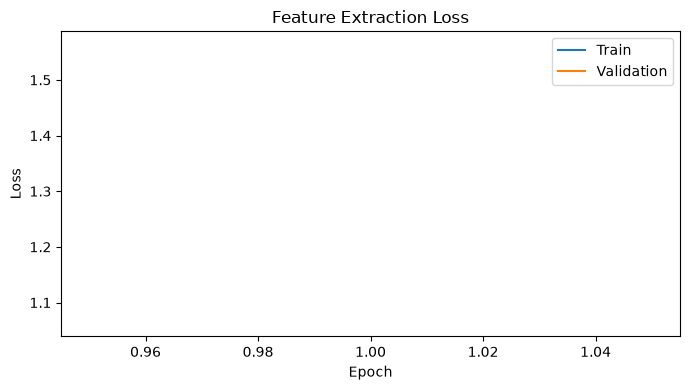

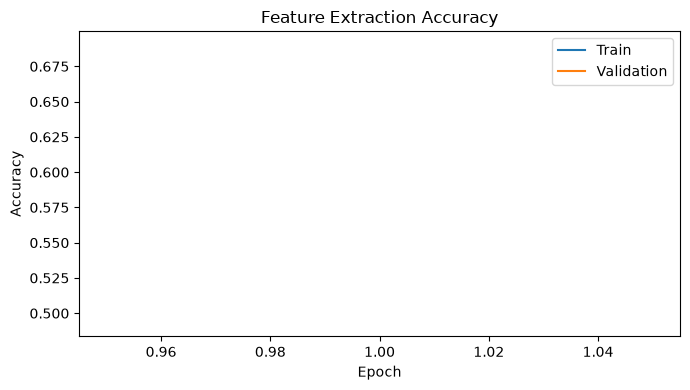

In [19]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_loss"], label="Train")
    plt.plot(epochs, history["validation_loss"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_accuracy"], label="Train")
    plt.plot(epochs, history["validation_accuracy"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(feature_history, "Feature Extraction")

### 18) 2단계: Fine-Tuning 설정

Feature Extraction에서 가장 좋았던 상태를 불러옵니다. 그다음 `layer4`와 `fc`만 학습 가능하게 설정합니다.

```text
conv1 ~ layer3: 동결 유지
layer4: 작은 학습률로 미세조정
fc: 조금 큰 학습률로 학습
```

사전학습 특징이 급격하게 바뀌지 않도록 `layer4`에는 작은 학습률을 적용합니다.

In [20]:
model.load_state_dict(feature_best_state)

model.layer4.requires_grad_(True)

model.fc.requires_grad_(True)

fine_tuning_parameter_count = count_trainable_parameters(model)

print("Feature Extraction 파라미터:", f"{feature_parameter_count:,}개")

print("Fine-Tuning 파라미터:", f"{fine_tuning_parameter_count:,}개")

Feature Extraction 파라미터: 5,130개
Fine-Tuning 파라미터: 8,398,858개


### 19) 2단계 학습 실행

Parameter Group(파라미터 그룹, 서로 다른 학습률을 적용하는 변수 묶음)을 사용합니다.

- `layer4`: 작은 학습률
- `fc`: 조금 큰 학습률

코드는 짧지만, 사전학습 계층과 새 분류층을 서로 다른 속도로 학습한다는 중요한 의미가 있습니다.

[Fine-Tuning] Epoch 1/1 | Train Acc 79.83% | Val Acc 84.00%

최고 검증 정확도: 84.00%
학습 시간: 0.06분


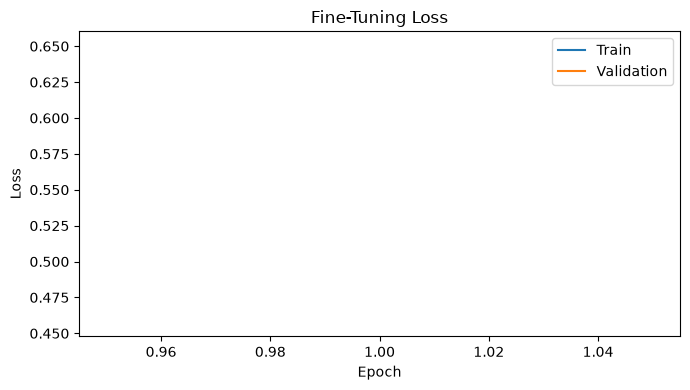

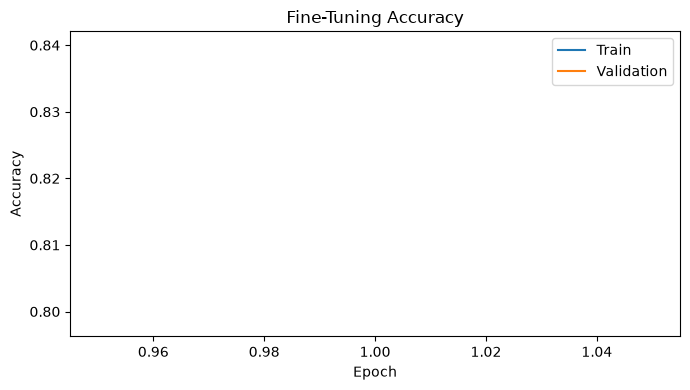

In [21]:
fine_tuning_optimizer = torch.optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": BACKBONE_LR,
    },
    {
        "params": model.fc.parameters(),
        "lr": FC_LR,
    },
])

(
    fine_history,
    fine_best_state,
    fine_best_accuracy,
    fine_time,
) = fit(
    model,
    train_loader,
    validation_loader,
    fine_tuning_optimizer,
    FINE_TUNING_EPOCHS,
    "Fine-Tuning",
)

print()

print("최고 검증 정확도:", f"{fine_best_accuracy * 100:.2f}%")

print("학습 시간:", f"{fine_time / 60:.2f}분")

plot_history(fine_history, "Fine-Tuning")

### 20) 두 단계 테스트 비교

검증 정확도가 가장 높았던 Feature Extraction 모델과 Fine-Tuning 모델을 같은 시험 데이터로 평가합니다.

방법                            학습 파라미터       시험 정확도        학습 시간
------------------------------------------------------------------
Feature Extraction              5,130       68.20%       0.06분
Fine-Tuning                 8,398,858       84.20%       0.06분


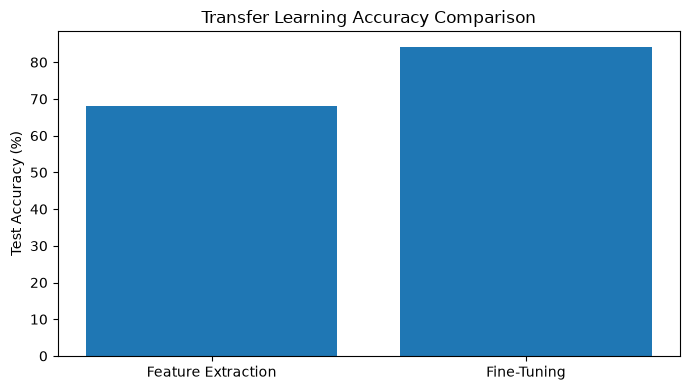

In [22]:
model.load_state_dict(feature_best_state)

feature_test_loss, feature_test_accuracy = run_one_epoch(
    model,
    test_loader,
)

model.load_state_dict(fine_best_state)

fine_test_loss, fine_test_accuracy = run_one_epoch(
    model,
    test_loader,
)

print(f"{'방법':<22} {'학습 파라미터':>14} {'시험 정확도':>12} {'학습 시간':>12}")

print("-" * 66)

print(
    f"{'Feature Extraction':<22} "
    f"{feature_parameter_count:>14,} "
    f"{feature_test_accuracy * 100:>11.2f}% "
    f"{feature_time / 60:>10.2f}분"
)

print(
    f"{'Fine-Tuning':<22} "
    f"{fine_tuning_parameter_count:>14,} "
    f"{fine_test_accuracy * 100:>11.2f}% "
    f"{fine_time / 60:>10.2f}분"
)

methods = ["Feature Extraction", "Fine-Tuning"]

accuracies = [feature_test_accuracy * 100, fine_test_accuracy * 100]

plt.figure(figsize=(7, 4))

plt.bar(methods, accuracies)

plt.ylabel("Test Accuracy (%)")

plt.title("Transfer Learning Accuracy Comparison")

plt.tight_layout()

plt.show()

### 21) 예측 결과 수집 함수

Fine-Tuning 최고 모델을 사용하여 다음 정보를 수집합니다.

- 실제 클래스
- 예측 클래스
- 예측 확률

In [23]:
model.load_state_dict(fine_best_state)

model.eval()

def collect_predictions(model, data_loader):
    all_labels = []
    all_predictions = []
    all_confidences = []

    with torch.inference_mode():
        for images, labels in data_loader:
            logits = model(images.to(device))
            probabilities = torch.softmax(logits, dim=1)

            confidences, predictions = probabilities.max(dim=1)

            all_labels.append(labels)
            all_predictions.append(predictions.cpu())
            all_confidences.append(confidences.cpu())

    return (
        torch.cat(all_labels),
        torch.cat(all_predictions),
        torch.cat(all_confidences),
    )

test_labels, test_predictions, test_confidences = collect_predictions(
    model,
    test_loader,
)

print("수집한 예측 수:", len(test_predictions))

수집한 예측 수: 1000


### 22) Confusion Matrix 준비

Confusion Matrix(컨퓨전 매트릭스, 혼동행렬)는 실제 클래스와 예측 클래스의 관계를 보여줍니다.

```text
대각선: 올바른 예측
대각선 밖: 서로 혼동한 예측
```

In [24]:
def make_confusion_matrix(labels, predictions, number_of_classes=10):
    matrix = torch.zeros(
        number_of_classes,
        number_of_classes,
        dtype=torch.int64,
    )

    for true_label, predicted_label in zip(labels, predictions):
        matrix[true_label, predicted_label] += 1

    return matrix

### 23) Confusion Matrix 시각화

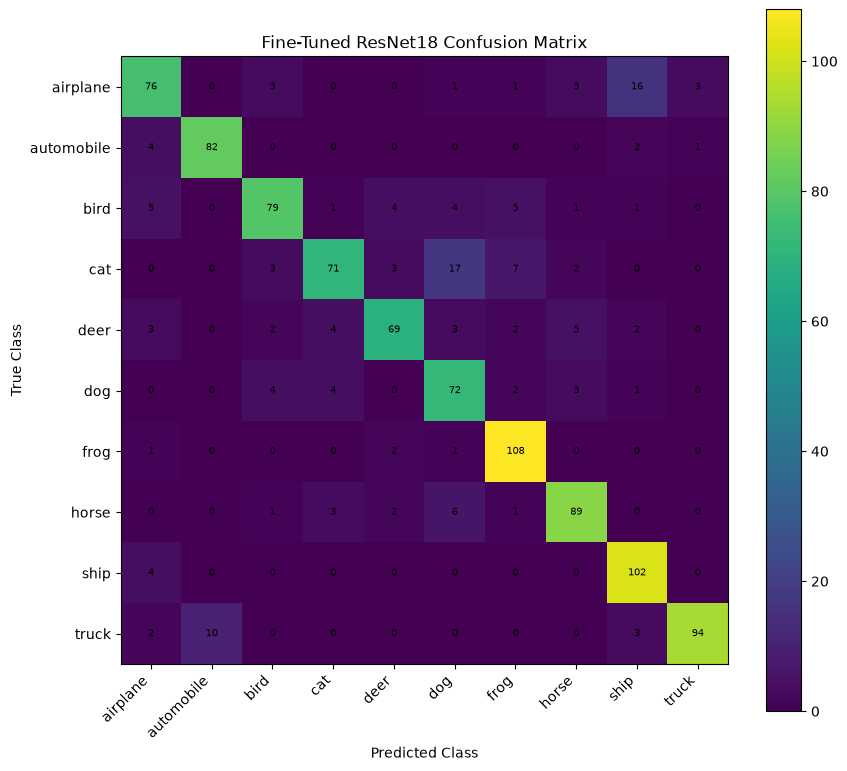

클래스별 정확도


In [25]:
confusion_matrix = make_confusion_matrix(
    test_labels,
    test_predictions,
)

plt.figure(figsize=(9, 8))

plt.imshow(confusion_matrix.numpy())

plt.colorbar()

plt.xticks(range(10), class_names, rotation=45, ha="right")

plt.yticks(range(10), class_names)

plt.xlabel("Predicted Class")

plt.ylabel("True Class")

plt.title("Fine-Tuned ResNet18 Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            confusion_matrix[row, column].item(),
            ha="center",
            va="center",
            fontsize=7,
        )

plt.tight_layout()

plt.show()

print("클래스별 정확도")

### 24) 클래스별 정확도 확인

In [26]:
for class_index, class_name in enumerate(class_names):
    total = confusion_matrix[class_index].sum().item()
    correct = confusion_matrix[class_index, class_index].item()
    accuracy = correct / total if total > 0 else 0

    print(f"{class_name:10s}: {accuracy * 100:6.2f}%")

airplane  :  73.79%
automobile:  92.13%
bird      :  79.00%
cat       :  68.93%
deer      :  76.67%
dog       :  83.72%
frog      :  96.43%
horse     :  87.25%
ship      :  96.23%
truck     :  86.24%


### 25) 오분류 데이터 확인

모델이 높은 확률로 틀린 이미지를 확인하면 어떤 특징을 잘못 사용했는지 추정할 수 있습니다.

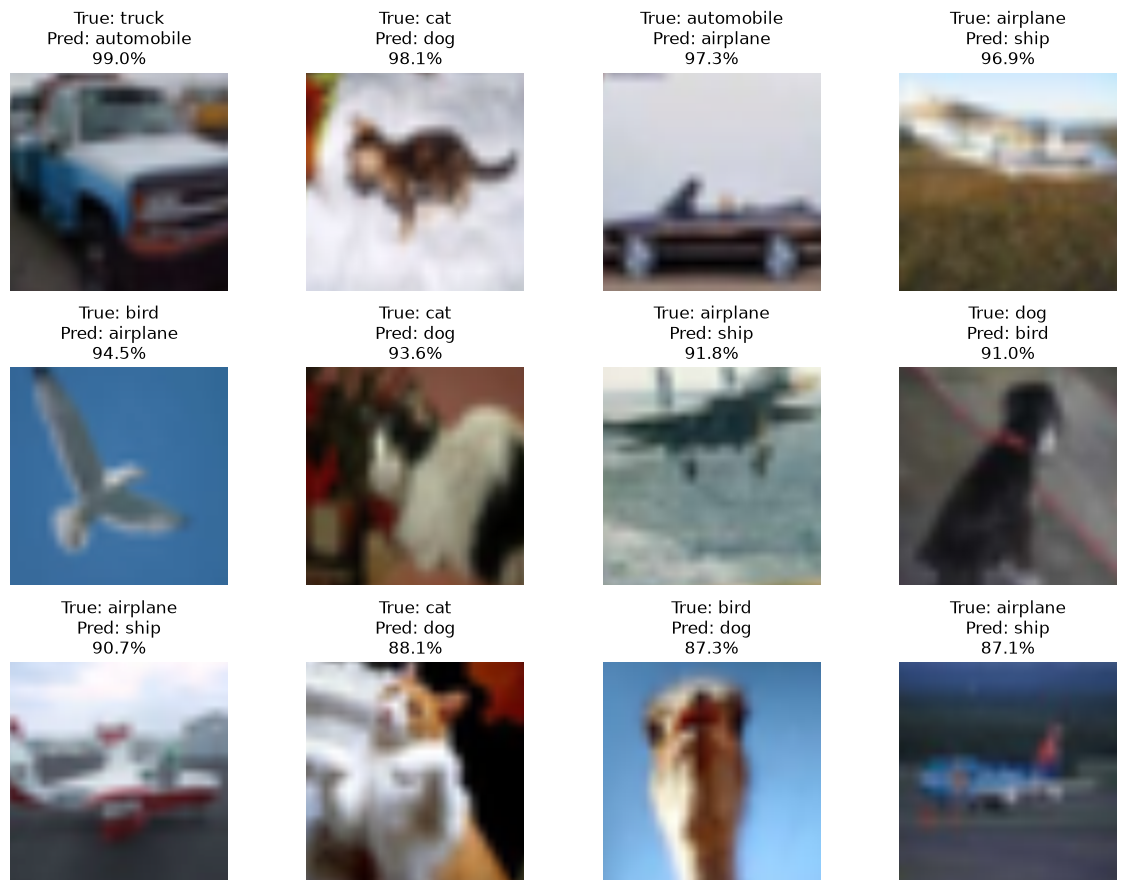

In [27]:
wrong_indices = torch.where(
    test_predictions != test_labels
)[0]

if len(wrong_indices) == 0:
    print("오답이 없습니다.")
else:
    # 높은 확률의 오답부터 확인합니다.
    wrong_confidences = test_confidences[wrong_indices]
    order = torch.argsort(wrong_confidences, descending=True)
    selected_indices = wrong_indices[order][:12]

    plt.figure(figsize=(12, 9))

    for plot_index, dataset_index in enumerate(selected_indices):
        image, true_label = test_dataset[dataset_index.item()]
        predicted_label = test_predictions[dataset_index].item()
        confidence = test_confidences[dataset_index].item()

        plt.subplot(3, 4, plot_index + 1)
        plt.imshow(denormalize(image).permute(1, 2, 0))
        plt.title(
            f"True: {class_names[true_label]}\n"
            f"Pred: {class_names[predicted_label]}\n"
            f"{confidence * 100:.1f}%"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### 26) Checkpoint 저장과 복원

가중치만 저장하면 구조와 데이터가 분리되어 관리가 쉽습니다.

```text
모델 구조 생성
→ 저장된 state_dict 불러오기
→ 평가 모드 설정
```

In [28]:
MODEL_PATH = MODEL_DIR / "ch05_2_best_resnet18_transfer_learning.pt"

checkpoint = {
    "model_name": "resnet18_transfer_learning",
    "number_of_classes": 10,
    "class_names": class_names,
    "model_state_dict": fine_best_state,
    "validation_accuracy": fine_best_accuracy,
    "test_accuracy": fine_test_accuracy,
}

torch.save(checkpoint, MODEL_PATH)

restored_model = create_resnet18(
    number_of_classes=10,
    pretrained=False,
).to(device)

saved_checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True,
)

restored_model.load_state_dict(
    saved_checkpoint["model_state_dict"]
)

restored_model.eval()

with torch.inference_mode():
    restored_output = restored_model(dummy_input)

print("저장 경로:", MODEL_PATH)
print("저장 클래스 수:", saved_checkpoint["number_of_classes"])
print("복원 모델 출력 Shape:", restored_output.shape)

저장 경로: models/ch05_6_best_resnet18_transfer_learning.pt
저장 클래스 수: 10
복원 모델 출력 Shape: torch.Size([2, 10])


## 핵심 정리

- Feature Extraction은 Backbone을 동결하고 새 `fc`만 학습합니다.
- Fine-Tuning은 `layer4`와 `fc`를 함께 학습해 특징을 데이터에 맞춥니다.
- Fine-Tuning은 작은 학습률로 필요한 경우에 적용합니다.